# Phase 5B-1 — Classification thresholds and business policies

Evaluate HGB and LR, preserving RF's Phase 5A reference. No class weighting, resampling, model-family search, feature selection, held-out use or Phase 5B-2. Source baseline is fetched main `8587eb4`.

## Colab and reuse rationale

Upload this notebook, preprocessing.py, 02_cleaned_dataset.csv, 03_split_indices.json, 07_threshold_decision_analysis.ipynb and 06_nested_cv_targeting_summary.md; or set PROJECT_DIR to mounted Drive. Standard packages/sklearn >=1.2 suffice. The original dataset and prior summaries are optional runtime integrity-check files. Only the new Markdown summary is exported; save the executed notebook for tables/plots. No fitted model, new split or processed data export.

Review confirmed Phase 5A saved parameter decisions and aggregate results, not fitted estimators/row probabilities. Reuse its training-only hyperparameters for each identical outer fold, validating their approved grid membership and source code provenance. Regenerate only selected estimators and training-side OOF probabilities: 60 fits instead of 535 repeated-grid fits. No new hyperparameters are chosen from outer labels. Require every .50 baseline score and pooled Top-K result to reproduce Phase 5A before accepting regeneration.

## 1. Validate exact data/order and prior selection provenance

Only development rows are parsed; the saved hash binds row order/values and the outer fold checksum matches Phase 5A. No new split. All prior files stay unchanged.


In [1]:
from pathlib import Path
import sys,json,hashlib,warnings,time,ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import BaseEstimator,TransformerMixin,clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix
from threadpoolctl import threadpool_limits
from IPython.display import display
PROJECT_DIR=Path.cwd()
required=['preprocessing.py','02_cleaned_dataset.csv','03_split_indices.json','06_nested_cv_targeting_summary.md','06_nested_cv_targeting.ipynb']
if any(not (PROJECT_DIR/n).is_file() for n in required):
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Place the required files in PROJECT_DIR') from exc
    files.upload()
if any(not (PROJECT_DIR/n).is_file() for n in required):raise FileNotFoundError(required)
sys.path.insert(0,str(PROJECT_DIR))
from preprocessing import make_preprocessor,make_cv,FEATURES,CATEGORICAL,NUMERICAL,RECENCY
BASE_MAIN='8587eb4'

def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
input_hashes={n:sha(PROJECT_DIR/n) for n in required}
for n in ['dataset.csv','04_baseline_summary.md','05_model_comparison_summary.md','05b_hist_gradient_boosting_summary.md']:
    if (PROJECT_DIR/n).is_file():input_hashes[n]=sha(PROJECT_DIR/n)
saved=json.loads((PROJECT_DIR/'03_split_indices.json').read_text())
assert input_hashes['02_cleaned_dataset.csv']==saved['input_sha256'] and saved['row_count']==41176
idx=np.asarray(saved['development_indices'],dtype=int);held=np.asarray(saved['held_out_indices'],dtype=int)
assert len(idx)==32940 and len(held)==8236 and len(np.unique(idx))==len(idx) and len(np.unique(held))==len(held)
assert not np.intersect1d(idx,held).size
np.testing.assert_array_equal(np.sort(np.r_[idx,held]),np.arange(41176))
keep=set(idx.tolist())
dev=pd.read_csv(PROJECT_DIR/'02_cleaned_dataset.csv',float_precision='round_trip',skiprows=lambda n:n>0 and n-1 not in keep)
assert dev.shape==(32940,16) and dev.columns.tolist()==FEATURES+['y']
dev.index=np.sort(idx);dev=dev.loc[idx].copy();snapshot=dev.copy(deep=True)
assert not dev.isna().any().any() and dev.y.isin([0,1]).all()
assert np.isfinite(dev[NUMERICAL+RECENCY].to_numpy()).all() and dev.recency_days.between(0,27).all()
assert dev.recency_available.isin([0,1]).all() and dev.loc[dev.recency_available.eq(0),'recency_days'].eq(0).all()
X=dev[FEATURES].copy();y=dev.y.copy();outer_folds=list(make_cv().split(X,y))
for (a,b),(aa,bb) in zip(outer_folds,make_cv().split(X,y)):
    np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb)
outer_hash=hashlib.sha256(b''.join(idx[b].astype('<i8').tobytes() for _,b in outer_folds)).hexdigest()
assert outer_hash=='6016ca88c4c344724075ade804828d47f03a69bf7337f5287cee0f4a444457c4'
assert all(not np.intersect1d(idx[a],held).size and not np.intersect1d(idx[b],held).size for a,b in outer_folds)
old_text=(PROJECT_DIR/'06_nested_cv_targeting_summary.md').read_text()
oldnb=json.loads((PROJECT_DIR/'06_nested_cv_targeting.ipynb').read_text())
oldcode='\n'.join(''.join(c['source']) for c in oldnb['cells'] if c['cell_type']=='code')
assert 'search.fit(outer_X,outer_y)' in oldcode and 'best_parameters' in oldcode
assert "json.dumps(search.best_params_,sort_keys=True)" in oldcode
assert 'inner_folds=list(make_cv().split(outer_X,outer_y))' in oldcode

def historical_table(heading):
    lines=[]
    for line in old_text.split(heading,1)[1].splitlines():
        if line.startswith('| '):lines.append(line)
        elif lines:break
    assert len(lines)>2
    cols=[a.strip() for a in lines[0].split('|')[1:-1]]
    return pd.DataFrame([[a.strip() for a in l.split('|')[1:-1]] for l in lines[2:]],columns=cols)
old_selections=historical_table('## Fold-specific selected hyperparameters')
old_results=historical_table('## Individual outer-fold predictive results')
old_pooled=historical_table('## Business targeting — pooled nested outer OOF ranks')
old_local_summary=historical_table('Mean and sample SD across the five cohorts')
old_ast=ast.parse(oldcode)
old_grids=ast.literal_eval(next(n.value for n in old_ast.body if isinstance(n,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='GRIDS' for t in n.targets)))
MODELS=['HistGradientBoosting','LogisticRegression']
APPROVED_GRIDS={
 'LogisticRegression':{'classifier__C':[.1,1.,10.]},
 'HistGradientBoosting':{'classifier__learning_rate':[.05,.1],'classifier__max_iter':[100,200],
 'classifier__max_leaf_nodes':[15,31],'classifier__l2_regularization':[0.,1.]}}
for m in MODELS:
    assert old_grids[m]==APPROVED_GRIDS[m]
    assert len(old_selections.loc[old_selections.model.eq(m)])==5
    for s in old_selections.loc[old_selections.model.eq(m),'best_parameters']:
        assert json.loads(s) in list(ParameterGrid(APPROVED_GRIDS[m]))
print('Latest main:',BASE_MAIN,'| exact Phase 5A development/fold hash verified:',outer_hash)
print('No reusable fitted-model/row-prediction artifact was published. Reuse verified training-only parameter selections, not outer-label choices.')
print('Planned regeneration: 50 selected-model training-side OOF fits + 10 outer-training refits = 60; no grid/RF rerun.')



Latest main: 8587eb4 | exact Phase 5A development/fold hash verified: 6016ca88c4c344724075ade804828d47f03a69bf7337f5287cee0f4a444457c4
No reusable fitted-model/row-prediction artifact was published. Reuse verified training-only parameter selections, not outer-label choices.
Planned regeneration: 50 selected-model training-side OOF fits + 10 outer-training refits = 60; no grid/RF rerun.


## 2. Predetermined objectives and protected fit partitions

Threshold grid is 0.10 to 0.60 in steps of 0.05, including unchanged 0.50. Rule is probability >=threshold. F1 objective: maximize training-side OOF F1, exact ties choose higher threshold. Illustrative precision objective: among positive-volume candidates with empirical precision >=50%, maximize recall, ties choose precision then higher threshold. This 50% target is a research assumption, not a bank policy or out-of-sample guarantee. If no threshold qualifies, report none feasible and abstain; do not label zero-division precision as meeting target.

Synthetic checks cover determinism, tie-breaking and no-feasible candidates. All later selector calls accept only the current outer-training labels. Pipeline guards reject evaluation on fitting rows; outer prediction is blocked until threshold decisions are frozen. Reuse unchanged approved LR scaling/conditional recency and unscaled HGB numeric one-hot setup. No global encoder/scaler. Classes and finite values are checked; validation cannot refit preprocessing.


In [2]:
GRID=np.round(np.arange(.10,.601,.05),2)
assert GRID.tolist()==[.1,.15,.2,.25,.3,.35,.4,.45,.5,.55,.6]
MIN_PRECISION=.50  # illustrative research assumption, not a bank policy
METRICS=['Accuracy','Precision','Recall','F1','ROC_AUC','AP']
POLICIES=['Reference_0.50','Training_F1','Training_Precision50']

def metrics(actual,prob,pred):
    tn,fp,fn,tp=map(int,confusion_matrix(actual,pred,labels=[0,1]).ravel())
    return dict(Accuracy=accuracy_score(actual,pred),Precision=precision_score(actual,pred,zero_division=0),
        Recall=recall_score(actual,pred,zero_division=0),F1=f1_score(actual,pred,zero_division=0),
        ROC_AUC=roc_auc_score(actual,prob),AP=average_precision_score(actual,prob),
        predicted_positives=int(np.sum(pred)),positive_rate=float(np.mean(pred)),TN=tn,FP=fp,FN=fn,TP=tp)

def choose_thresholds(actual,prob):
    assert frozenset(actual.index)==CONTEXT['outer_train_key']
    assert not set(actual.index).intersection(CONTEXT['outer_val_key'])
    assert np.isfinite(prob).all()
    rows=[]
    for t in GRID:
        p=prob>=t
        rows.append({'threshold':float(t),'Precision':precision_score(actual,p,zero_division=0),
            'Recall':recall_score(actual,p,zero_division=0),'F1':f1_score(actual,p,zero_division=0),'predicted_positives':int(p.sum())})
    # Prespecified deterministic rules: maximum F1, ties -> highest threshold.
    f1=max(rows,key=lambda r:(r['F1'],r['threshold']))
    eligible=[r for r in rows if r['predicted_positives']>0 and r['Precision']>=MIN_PRECISION]
    # Precision objective: maximize recall subject to minimum precision; ties -> precision, threshold.
    constrained=max(eligible,key=lambda r:(r['Recall'],r['Precision'],r['threshold'])) if eligible else None
    return {'Reference_0.50':.5,'Training_F1':f1['threshold'],
            'Training_Precision50':constrained['threshold'] if constrained else None},rows

class FiniteGuard(TransformerMixin,BaseEstimator):
    def __init__(self,scaled=False):self.scaled=scaled
    def check(self,z):
        assert isinstance(z,np.ndarray) and np.isfinite(z).all() and np.isin(z[:,:-9],[0.,1.]).all()
        assert np.isin(z[:,-1],[0.,1.]).all() and (z[z[:,-1]==0,-2]==0).all()
        if not self.scaled:assert ((z[:,-2]>=0)&(z[:,-2]<=27)).all()
        return z
    def fit(self,z,y=None):self.check(z);self.n_features_in_=z.shape[1];return self
    def transform(self,z):self.check(z);assert z.shape[1]==self.n_features_in_;return z
    def get_feature_names_out(self,input_features=None):return np.asarray(input_features,dtype=object)

def signature(pre):
    ct=pre.named_steps['preprocessor'];num=ct.named_transformers_['numerical'];rec=ct.named_transformers_['recency']
    sig={'categories':[a.tolist() for a in ct.named_transformers_['categorical'].categories_]}
    if hasattr(num,'mean_'):sig['numeric']=[num.mean_.tolist(),num.var_.tolist(),num.scale_.tolist(),np.asarray(num.n_samples_seen_).tolist()]
    if hasattr(rec,'mean_'):sig['recency']=[rec.mean_,rec.var_,rec.scale_,rec.n_available_]
    return sig
CONTEXT={};FIT_AUDIT=[];PRED_AUDIT=[];WARNING_LOG=[]
class AuditedPipeline(Pipeline):
    def fit(self,X,y=None,**params):
        key=frozenset(X.index)
        assert key in CONTEXT['oof_train_keys'] or key==CONTEXT['outer_train_key']
        assert not key.intersection(CONTEXT['outer_val_key']) and not set(X.index).intersection(held)
        assert np.array_equal(X.index,y.index)
        pre=self.named_steps['preprocessing'];assert not hasattr(pre.named_steps['preprocessor'],'transformers_')
        with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=1):
            warnings.simplefilter('always');result=super().fit(X,y,**params)
        ct=pre.named_steps['preprocessor'];enc=ct.named_transformers_['categorical']
        for c,levels in zip(CATEGORICAL,enc.categories_):np.testing.assert_array_equal(levels,np.sort(X[c].unique()))
        assert enc.drop is None and enc.handle_unknown=='ignore'
        num=ct.named_transformers_['numerical'];rec=ct.named_transformers_['recency']
        if CONTEXT['model']=='LogisticRegression':
            np.testing.assert_allclose(num.mean_,X[NUMERICAL].mean(),rtol=1e-12,atol=1e-12)
            np.testing.assert_allclose(num.var_,X[NUMERICAL].var(ddof=0),rtol=1e-12,atol=1e-12)
            sd=np.sqrt(X[NUMERICAL].var(ddof=0).to_numpy());sd[sd==0]=1
            np.testing.assert_allclose(num.scale_,sd,rtol=1e-12,atol=1e-12)
            assert np.all(np.asarray(num.n_samples_seen_)==len(X))
            observed=X.loc[X.recency_available.eq(1),'recency_days'].to_numpy()
            mean=observed.mean() if len(observed) else 0.;var=observed.var(ddof=0) if len(observed) else 0.;sd=np.sqrt(var) if var>0 else 1.
            assert rec.n_available_==len(observed)
            np.testing.assert_allclose([rec.mean_,rec.var_,rec.scale_],[mean,var,sd],rtol=1e-12)
        else:
            assert not hasattr(num,'mean_') and not hasattr(rec,'mean_')
        clf=self.named_steps['classifier'];np.testing.assert_array_equal(clf.classes_,[0,1])
        assert clf.class_weight is None and clf.random_state==42
        if hasattr(clf,'coef_'):assert np.isfinite(clf.coef_).all() and np.isfinite(clf.intercept_).all()
        if CONTEXT['model']=='HistGradientBoosting':
            assert clf.categorical_features is None and clf.early_stopping is False and clf.n_iter_==clf.max_iter
        self._fit_rows=key
        role='outer-training refit' if key==CONTEXT['outer_train_key'] else 'training-side OOF fit'
        for w in caught:WARNING_LOG.append({'model':CONTEXT['model'],'outer_fold':CONTEXT['outer_fold'],'role':role,'category':w.category.__name__,'message':str(w.message)})
        FIT_AUDIT.append({'model':CONTEXT['model'],'outer_fold':CONTEXT['outer_fold'],'role':role,'rows':len(X),'warnings':len(caught),'status':'PASS'})
        return result
    def predict_proba(self,X,**params):
        key=frozenset(X.index);assert not key.intersection(self._fit_rows)
        if CONTEXT['role']=='training-side OOF':assert key in CONTEXT['oof_val_keys'] and not key.intersection(CONTEXT['outer_val_key'])
        else:assert CONTEXT['role']=='outer validation' and CONTEXT['thresholds_frozen'] and key==CONTEXT['outer_val_key']
        assert not set(X.index).intersection(held)
        pre=self.named_steps['preprocessing'];before=signature(pre);z=pre.transform(X);self.named_steps['finite_guard'].transform(z)
        np.testing.assert_array_equal(z[:,-1],X.recency_available)
        rec=pre.named_steps['preprocessor'].named_transformers_['recency']
        if hasattr(rec,'mean_'):
            mask=X.recency_available.eq(1).to_numpy()
            np.testing.assert_allclose(z[mask,-2],(X.loc[mask,'recency_days']-rec.mean_)/rec.scale_)
        else:np.testing.assert_array_equal(z[:,-9:],X[NUMERICAL+RECENCY].to_numpy())
        with threadpool_limits(limits=1):out=super().predict_proba(X,**params)
        assert signature(pre)==before and np.isfinite(out).all() and ((out>=0)&(out<=1)).all()
        PRED_AUDIT.append({'model':CONTEXT['model'],'outer_fold':CONTEXT['outer_fold'],'role':CONTEXT['role'],'rows':len(X),'status':'PASS'})
        return out

def factory(model,params):
    if model=='LogisticRegression':
        name='logistic_regression';clf=LogisticRegression(C=1.,max_iter=1000,solver='lbfgs',random_state=42,class_weight=None)
    elif model=='HistGradientBoosting':
        name='decision_tree';clf=HistGradientBoostingClassifier(learning_rate=.1,max_iter=100,max_leaf_nodes=31,
            l2_regularization=0.,early_stopping=False,random_state=42,class_weight=None,categorical_features=None)
    else:raise ValueError(model)
    p=AuditedPipeline([('preprocessing',make_preprocessor(name)),('finite_guard',FiniteGuard(scaled=model=='LogisticRegression')),('classifier',clf)])
    return p.set_params(**params)
# Explicit policy-selector tests use only synthetic examples, not outer labels.
_test_key=frozenset(range(4));CONTEXT.update(outer_train_key=_test_key,outer_val_key=frozenset([999999]))
a=pd.Series([1,0,1,0],index=range(4));prob=np.array([.01,.02,.03,.04])
chosen,table=choose_thresholds(a,prob)
assert chosen['Training_Precision50'] is None  # no positive selection can reach the minimum
assert chosen['Training_F1']==.6  # all F1=0; highest-threshold tie-break
chosen2,_=choose_thresholds(a,prob);assert chosen==chosen2
print('Predeclared threshold grid/rules and no-feasible-candidate behavior validated.')



Predeclared threshold grid/rules and no-feasible-candidate behavior validated.


## 3. Training-side selection, freeze, then outer evaluation

For each model/outer fold, use its documented Phase 5A inner-AP winner. Generate cross-fitted probabilities on the outer-training partition with five fresh selected-model pipelines. Hyperparameters were previously selected using that whole outer-training partition, so these training-side OOF values are conditional on a training-selected configuration: they are threshold-fitting data, not unbiased reported inner performance. Outer validation remains excluded from both decisions.

Choose both thresholds using only those training labels/predictions and repeat selection to check reproducibility. Freeze decisions, refit the selected model on outer-training rows, and only then predict/evaluate outer validation. Store .50, F1-selected and precision-constrained predictions. Exactly one outer probability per development record; three policy decisions use that same probability. Verify reference scores reproduce Phase 5A. No RF/grid rerun.


In [3]:
started=time.perf_counter();policy_rows=[];threshold_rows=[];training_tables=[];cost_rows=[];oof={}
for model in MODELS:oof[model]={'prob':np.full(len(X),np.nan),'coverage':np.zeros(len(X),int),
    'pred':{p:np.full(len(X),-1,int) for p in POLICIES}}
for outer_fold,(otr,ova) in enumerate(outer_folds,start=1):
    train_X=X.iloc[otr];train_y=y.iloc[otr]
    training_folds=list(make_cv().split(train_X,train_y))
    for (a,b),(aa,bb) in zip(training_folds,make_cv().split(train_X,train_y)):
        np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb)
    for model in MODELS:
        selection=old_selections.loc[old_selections.model.eq(model)&old_selections.outer_fold.eq(str(outer_fold))].iloc[0]
        params=json.loads(selection.best_parameters)
        CONTEXT.update(model=model,outer_fold=outer_fold,outer_train_key=frozenset(train_X.index),outer_val_key=frozenset(X.iloc[ova].index),
            oof_train_keys={frozenset(train_X.iloc[a].index) for a,b in training_folds},
            oof_val_keys={frozenset(train_X.iloc[b].index) for a,b in training_folds},role='training-side OOF',thresholds_frozen=False)
        t=time.perf_counter();train_prob=np.full(len(train_X),np.nan);coverage=np.zeros(len(train_X),int)
        for a,b in training_folds:
            p=factory(model,params);p.fit(train_X.iloc[a],train_y.iloc[a])
            train_prob[b]=p.predict_proba(train_X.iloc[b])[:,list(p.classes_).index(1)];coverage[b]+=1
        assert (coverage==1).all() and np.isfinite(train_prob).all()
        chosen,training_table=choose_thresholds(train_y,train_prob)
        repeated,_=choose_thresholds(train_y,train_prob);assert chosen==repeated
        # Freeze decisions BEFORE predicting/accessing outcome labels in this outer validation cohort.
        frozen=dict(chosen);CONTEXT['thresholds_frozen']=True
        for row in training_table:training_tables.append({'model':model,'outer_fold':outer_fold,**row})
        for policy,threshold in chosen.items():
            source=next((row for row in training_table if row['threshold']==threshold),None)
            threshold_rows.append({'model':model,'outer_fold':outer_fold,'policy':policy,'threshold':threshold if threshold is not None else 'none feasible',
                'training_feasible':threshold is not None,'training_OOF_precision':source['Precision'] if source else 'not applicable',
                'training_OOF_recall':source['Recall'] if source else 'not applicable','best_parameters':selection.best_parameters})
        p=factory(model,params);p.fit(train_X,train_y)
        CONTEXT['role']='outer validation'
        outer_prob=p.predict_proba(X.iloc[ova])[:,list(p.classes_).index(1)]
        assert chosen==frozen
        outer_actual=y.iloc[ova]  # used for evaluation only after thresholds frozen
        oof[model]['prob'][ova]=outer_prob;oof[model]['coverage'][ova]+=1
        for policy,threshold in frozen.items():
            pred=(outer_prob>=threshold).astype(int) if threshold is not None else np.zeros(len(ova),int)
            oof[model]['pred'][policy][ova]=pred
            row={'model':model,'outer_fold':outer_fold,'policy':policy,**metrics(outer_actual,outer_prob,pred)}
            policy_rows.append(row)
        reference=old_results.loc[old_results.model.eq(model)&old_results.outer_fold.eq(str(outer_fold))].iloc[0]
        current=policy_rows[-3]
        np.testing.assert_allclose([current[m] for m in METRICS],reference[METRICS].astype(float).to_numpy(),rtol=0,atol=5.1e-7)
        cost_rows.append({'model':model,'outer_fold':outer_fold,'training_OOF_fits':5,'outer_refits':1,'wall_seconds':time.perf_counter()-t})
        print('Complete',model,'outer fold',outer_fold,'thresholds:',frozen,flush=True)
for model in MODELS:
    assert (oof[model]['coverage']==1).all() and np.isfinite(oof[model]['prob']).all()
    for policy in POLICIES:assert np.isin(oof[model]['pred'][policy],[0,1]).all()
assert len(FIT_AUDIT)==60 and len(PRED_AUDIT)==60
assert sum(r['role']=='training-side OOF fit' for r in FIT_AUDIT)==50
assert sum(r['role']=='outer-training refit' for r in FIT_AUDIT)==10
policy_results=pd.DataFrame(policy_rows);thresholds=pd.DataFrame(threshold_rows);cost=pd.DataFrame(cost_rows)
assert np.isfinite(policy_results[METRICS+['predicted_positives','positive_rate','TN','FP','FN','TP']].to_numpy()).all()
assert policy_results.groupby(['model','outer_fold']).ROC_AUC.nunique().eq(1).all()
assert policy_results.groupby(['model','outer_fold']).AP.nunique().eq(1).all()
print('All regenerated .50 reference fold scores reproduce Phase 5A; thresholds frozen before each outer evaluation.')
display(policy_results);display(thresholds)



Complete HistGradientBoosting outer fold 1 thresholds: {'Reference_0.50': 0.5, 'Training_F1': 0.2, 'Training_Precision50': 0.35}
Complete LogisticRegression outer fold 1 thresholds: {'Reference_0.50': 0.5, 'Training_F1': 0.2, 'Training_Precision50': 0.35}
Complete HistGradientBoosting outer fold 2 thresholds: {'Reference_0.50': 0.5, 'Training_F1': 0.2, 'Training_Precision50': 0.35}
Complete LogisticRegression outer fold 2 thresholds: {'Reference_0.50': 0.5, 'Training_F1': 0.2, 'Training_Precision50': 0.35}
Complete HistGradientBoosting outer fold 3 thresholds: {'Reference_0.50': 0.5, 'Training_F1': 0.2, 'Training_Precision50': 0.35}
Complete LogisticRegression outer fold 3 thresholds: {'Reference_0.50': 0.5, 'Training_F1': 0.2, 'Training_Precision50': 0.35}
Complete HistGradientBoosting outer fold 4 thresholds: {'Reference_0.50': 0.5, 'Training_F1': 0.15, 'Training_Precision50': 0.35}
Complete LogisticRegression outer fold 4 thresholds: {'Reference_0.50': 0.5, 'Training_F1': 0.2, 'Trai

,model,outer_fold,policy,Accuracy,Precision,Recall,F1,ROC_AUC,AP,predicted_positives,positive_rate,TN,FP,FN,TP
0,HistGradientBoosting,1,Reference_0.50,0.899666,0.650558,0.235849,0.346192,0.810998,0.450109,269,0.040832,5752,94,567,175
1,HistGradientBoosting,1,Training_F1,0.867183,0.435749,0.607817,0.507597,0.810998,0.450109,1035,0.157104,5262,584,291,451
2,HistGradientBoosting,1,Training_Precision50,0.891621,0.525547,0.388140,0.446512,0.810998,0.450109,548,0.083182,5586,260,454,288
3,LogisticRegression,1,Reference_0.50,0.899211,0.671053,0.206199,0.315464,0.773340,0.432797,228,0.034608,5771,75,589,153
4,LogisticRegression,1,Training_F1,0.871281,0.438799,0.512129,0.472637,0.773340,0.432797,866,0.131451,5360,486,362,380
5,LogisticRegression,1,Training_Precision50,0.892532,0.535270,0.347709,0.421569,0.773340,0.432797,482,0.073163,5622,224,484,258
6,HistGradientBoosting,2,Reference_0.50,0.899211,0.668103,0.208895,0.318275,0.791971,0.442077,232,0.035216,5769,77,587,155
7,HistGradientBoosting,2,Training_F1,0.866424,0.429158,0.563342,0.487179,0.791971,0.442077,974,0.147845,5290,556,324,418
8,HistGradientBoosting,2,Training_Precision50,0.892532,0.532197,0.378706,0.442520,0.791971,0.442077,528,0.080146,5599,247,461,281
9,LogisticRegression,2,Reference_0.50,0.899970,0.698565,0.196765,0.307045,0.758226,0.420805,209,0.031724,5783,63,596,146


,model,outer_fold,policy,threshold,training_feasible,training_OOF_precision,training_OOF_recall,best_parameters
0,HistGradientBoosting,1,Reference_0.50,0.50,True,0.660063,0.213203,"{""classifier__l2_regularization"": 0.0, ""classi..."
1,HistGradientBoosting,1,Training_F1,0.20,True,0.429076,0.572583,"{""classifier__l2_regularization"": 0.0, ""classi..."
2,HistGradientBoosting,1,Training_Precision50,0.35,True,0.527404,0.369485,"{""classifier__l2_regularization"": 0.0, ""classi..."
3,LogisticRegression,1,Reference_0.50,0.50,True,0.682209,0.187268,"{""classifier__C"": 0.1}"
4,LogisticRegression,1,Training_F1,0.20,True,0.435503,0.495790,"{""classifier__C"": 0.1}"
5,LogisticRegression,1,Training_Precision50,0.35,True,0.524769,0.324688,"{""classifier__C"": 0.1}"
6,HistGradientBoosting,2,Reference_0.50,0.50,True,0.675761,0.216908,"{""classifier__l2_regularization"": 1.0, ""classi..."
7,HistGradientBoosting,2,Training_F1,0.20,True,0.430380,0.584035,"{""classifier__l2_regularization"": 1.0, ""classi..."
8,HistGradientBoosting,2,Training_Precision50,0.35,True,0.519059,0.371506,"{""classifier__l2_regularization"": 1.0, ""classi..."
9,LogisticRegression,2,Reference_0.50,0.50,True,0.674883,0.193668,"{""classifier__C"": 0.1}"


## 4. Honest policy results versus descriptive diagnostics

Fold-level policy metrics/confusion counts and five-fold mean/sample SD are proper outer evaluation of frozen decisions. Pooled policy metrics aggregate fold-specific decisions and are distinct from fold averages. Selected thresholds/frequencies and achieved outer precision reveal policy stability; a training precision constraint need not hold on a future cohort.

Descriptive threshold curves use the development outer-OOF labels only to explain trade-offs; do not choose a best threshold from them and claim unbiased performance. Actual policy thresholds were already frozen training-side. ROC-AUC/AP are invariant when only the decision threshold changes for the same probabilities; assertions enforce this.

Fixed-capacity Policy A ranks top 5/10/20% with deterministic saved-row tie-breaking, ceil capacity, and no fixed probability cutoff. Equal capacity across models; include unchanged RF history. Both pooled and fold-local views are reported, with pooled calibration/overlapping-training and rounding caveats. Fixed-rule Policy B controls a probability/precision/F1 research objective but produces variable contact volume. Neither establishes financial optimality or causal outreach impact.


In [4]:
means=policy_results.groupby(['model','policy'])[METRICS+['predicted_positives','positive_rate']].mean()
sds=policy_results.groupby(['model','policy'])[METRICS+['predicted_positives','positive_rate']].std(ddof=1)
comparison=pd.DataFrame(index=means.index)
for metric in METRICS+['predicted_positives','positive_rate']:
    comparison[metric+' mean ± SD']=[f'{means.loc[i,metric]:.6f} ± {sds.loc[i,metric]:.6f}' for i in means.index]
pooled_policies=pd.DataFrame([{'model':model,'policy':policy,**metrics(y,oof[model]['prob'],oof[model]['pred'][policy])}
    for model in MODELS for policy in POLICIES])
# Descriptive curves only: no threshold is chosen from these pooled evaluation labels.
diagnostic=pd.DataFrame([{'model':model,'threshold':float(t),**metrics(y,oof[model]['prob'],oof[model]['prob']>=t)}
    for model in MODELS for t in GRID])
assert diagnostic.groupby('model').ROC_AUC.nunique().eq(1).all() and diagnostic.groupby('model').AP.nunique().eq(1).all()
stability=thresholds.groupby(['model','policy','threshold'],dropna=False).size().rename('fold_count').reset_index()
constraint_status=policy_results.loc[policy_results.policy.eq('Training_Precision50')].groupby('model').Precision.agg(
    folds_at_or_above_50=lambda v:int((v>=MIN_PRECISION).sum()),outer_folds='size')

def topk(actual,prob,fraction,ties):
    k=int(np.ceil(len(actual)*fraction));order=np.lexsort((np.asarray(ties),-np.asarray(prob)))
    capture=int(np.asarray(actual)[order[:k]].sum());total=int(np.asarray(actual).sum());precision=capture/k
    return dict(contacts=k,captured_subscribers=capture,Precision_at_K=precision,Recall_at_K=capture/total,Lift_at_K=precision/(total/len(actual)))
capacity=[];local_capacity=[]
for model in MODELS:
    for f in [.05,.1,.2]:
        capacity.append({'model':model,'fraction':f,**topk(y,oof[model]['prob'],f,X.index)})
        for fold,(_,va) in enumerate(outer_folds,start=1):local_capacity.append({'model':model,'fraction':f,'outer_fold':fold,
            **topk(y.iloc[va],oof[model]['prob'][va],f,X.iloc[va].index)})
capacity=pd.DataFrame(capacity);local_capacity=pd.DataFrame(local_capacity)
for model in MODELS:
    old=old_pooled.loc[old_pooled.model.eq(model)].copy()
    new=capacity.loc[capacity.model.eq(model)]
    for c in ['contacts','captured_subscribers','Precision_at_K','Recall_at_K','Lift_at_K']:
        np.testing.assert_allclose(new[c].astype(float),old[c].astype(float),rtol=0,atol=5.1e-7)
rf_capacity=old_pooled.loc[old_pooled.model.eq('RandomForest')].copy()
capacity_comparison=pd.concat([capacity,rf_capacity],ignore_index=True)
local_summary=local_capacity.groupby(['model','fraction'])[['contacts','captured_subscribers','Precision_at_K','Recall_at_K','Lift_at_K']].agg(['mean','std']).reset_index()
local_summary.columns=['model','fraction','contacts_mean','contacts_SD','captured_mean','captured_SD','Precision_mean','Precision_SD','Recall_mean','Recall_SD','Lift_mean','Lift_SD']
rf_local=old_local_summary.loc[old_local_summary.model.eq('RandomForest')]
local_comparison=pd.concat([local_summary,rf_local],ignore_index=True)
assert local_capacity.groupby(['fraction','outer_fold']).contacts.nunique().eq(1).all()
rf_reference=old_results.loc[old_results.model.eq('RandomForest'),['model','outer_fold']+METRICS].copy()
for c in METRICS:rf_reference[c]=rf_reference[c].astype(float)
display(comparison);display(pooled_policies);display(diagnostic);display(stability);display(constraint_status)
display(capacity_comparison);display(local_comparison)



Accuracy mean ± SD  ... positive_rate mean ± SD
model                policy                                     ...                        
HistGradientBoosting Reference_0.50        0.899666 ± 0.000387  ...     0.036976 ± 0.003314
                     Training_F1           0.865270 ± 0.004506  ...     0.154250 ± 0.005088
                     Training_Precision50  0.891682 ± 0.002083  ...     0.081208 ± 0.003684
LogisticRegression   Reference_0.50        0.899180 ± 0.001207  ...     0.031815 ± 0.002083
                     Training_F1           0.871554 ± 0.003530  ...     0.128476 ± 0.003721
                     Training_Precision50  0.891651 ± 0.002716  ...     0.070067 ± 0.003342

[6 rows x 8 columns]

,model,policy,Accuracy,Precision,Recall,F1,ROC_AUC,AP,predicted_positives,positive_rate,TN,FP,FN,TP
0,HistGradientBoosting,Reference_0.50,0.899666,0.666667,0.218809,0.329479,0.794260,0.445335,1218,0.036976,28823,406,2899,812
1,HistGradientBoosting,Training_F1,0.865270,0.428459,0.586634,0.495223,0.794260,0.445335,5081,0.154250,26325,2904,1534,2177
2,HistGradientBoosting,Training_Precision50,0.891682,0.526729,0.379682,0.441278,0.794260,0.445335,2675,0.081208,27963,1266,2302,1409
3,LogisticRegression,Reference_0.50,0.899180,0.686069,0.193748,0.302164,0.761768,0.421094,1048,0.031815,28900,329,2992,719
4,LogisticRegression,Training_F1,0.871554,0.438563,0.500135,0.467330,0.761768,0.421094,4232,0.128476,26853,2376,1855,1856
5,LogisticRegression,Training_Precision50,0.891651,0.530763,0.330100,0.407044,0.761768,0.421094,2308,0.070067,28146,1083,2486,1225


,model,threshold,Accuracy,Precision,Recall,F1,ROC_AUC,AP,predicted_positives,positive_rate,TN,FP,FN,TP
0,HistGradientBoosting,0.10,0.823315,0.347550,0.647804,0.452390,0.794260,0.445335,6917,0.209988,24716,4513,1307,2404
1,HistGradientBoosting,0.15,0.859957,0.415952,0.601455,0.491792,0.794260,0.445335,5366,0.162902,26095,3134,1479,2232
2,HistGradientBoosting,0.20,0.866485,0.431396,0.582053,0.495526,0.794260,0.445335,5007,0.152004,26382,2847,1551,2160
3,HistGradientBoosting,0.25,0.870097,0.439677,0.557801,0.491745,0.794260,0.445335,4708,0.142927,26591,2638,1641,2070
4,HistGradientBoosting,0.30,0.880237,0.469324,0.482350,0.475748,0.794260,0.445335,3814,0.115786,27205,2024,1921,1790
5,HistGradientBoosting,0.35,0.891682,0.526729,0.379682,0.441278,0.794260,0.445335,2675,0.081208,27963,1266,2302,1409
6,HistGradientBoosting,0.40,0.897571,0.590155,0.297224,0.395341,0.794260,0.445335,1869,0.056740,28463,766,2608,1103
7,HistGradientBoosting,0.45,0.898998,0.629905,0.250876,0.358836,0.794260,0.445335,1478,0.044869,28682,547,2780,931
8,HistGradientBoosting,0.50,0.899666,0.666667,0.218809,0.329479,0.794260,0.445335,1218,0.036976,28823,406,2899,812
9,HistGradientBoosting,0.55,0.900000,0.699522,0.196982,0.307401,0.794260,0.445335,1045,0.031724,28915,314,2980,731


,model,policy,threshold,fold_count
0,HistGradientBoosting,Reference_0.50,0.50,5
1,HistGradientBoosting,Training_F1,0.15,1
2,HistGradientBoosting,Training_F1,0.20,4
3,HistGradientBoosting,Training_Precision50,0.35,5
4,LogisticRegression,Reference_0.50,0.50,5
5,LogisticRegression,Training_F1,0.20,5
6,LogisticRegression,Training_Precision50,0.35,5


,folds_at_or_above_50,outer_folds
model,,
HistGradientBoosting,5,5
LogisticRegression,5,5


,model,fraction,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K
0,HistGradientBoosting,0.05,1647,1005,0.6102,0.270816,5.41633
1,HistGradientBoosting,0.1,3294,1628,0.494232,0.438696,4.386958
2,HistGradientBoosting,0.2,6588,2377,0.360808,0.640528,3.202641
3,LogisticRegression,0.05,1647,962,0.584092,0.259229,5.184586
4,LogisticRegression,0.1,3294,1564,0.474803,0.42145,4.214497
5,LogisticRegression,0.2,6588,2257,0.342593,0.608192,3.040959
6,RandomForest,0.050000,1647,999,0.606557,0.269200,5.383994
7,RandomForest,0.100000,3294,1588,0.482089,0.427917,4.279170
8,RandomForest,0.200000,6588,2341,0.355343,0.630827,3.154136


,model,fraction,contacts_mean,contacts_SD,captured_mean,captured_SD,Precision_mean,Precision_SD,Recall_mean,Recall_SD,Lift_mean,Lift_SD
0,HistGradientBoosting,0.05,330.0,0.0,202.0,2.0,0.612121,0.006061,0.272164,0.002745,5.433389,0.054809
1,HistGradientBoosting,0.1,659.0,0.0,325.4,6.503845,0.493778,0.009869,0.438425,0.008686,4.382921,0.086838
2,HistGradientBoosting,0.2,1318.0,0.0,474.2,14.272351,0.359788,0.010829,0.638912,0.019242,3.193588,0.09618
3,LogisticRegression,0.05,330.0,0.0,192.6,8.38451,0.583636,0.025408,0.259496,0.011221,5.180487,0.224006
4,LogisticRegression,0.1,659.0,0.0,314.0,5.0,0.47648,0.007587,0.423066,0.006657,4.229372,0.066547
5,LogisticRegression,0.2,1318.0,0.0,451.2,14.75466,0.342337,0.011195,0.60792,0.019807,3.03868,0.099004
6,RandomForest,0.050000,330.000000,0.000000,199.600000,4.615192,0.604848,0.013985,0.268930,0.006214,5.368824,0.124058
7,RandomForest,0.100000,659.000000,0.000000,318.400000,10.761041,0.483156,0.016329,0.428990,0.014328,4.288602,0.143241
8,RandomForest,0.200000,1318.000000,0.000000,468.600000,10.212737,0.355539,0.007749,0.631366,0.013740,3.155871,0.068678


## 5. Diagnostic curves and frozen-policy outer diagnostics

First figure is descriptive: pooled outer-OOF precision/recall/F1/contact rate over the prespecified threshold grid. No global optimum is selected from it. Second compares recall by outer fold for the three already-frozen policies. Confusion matrices aggregate outer decisions, not in-sample fitting predictions. The .50 rule is unchanged. No threshold changes AP/ROC-AUC.


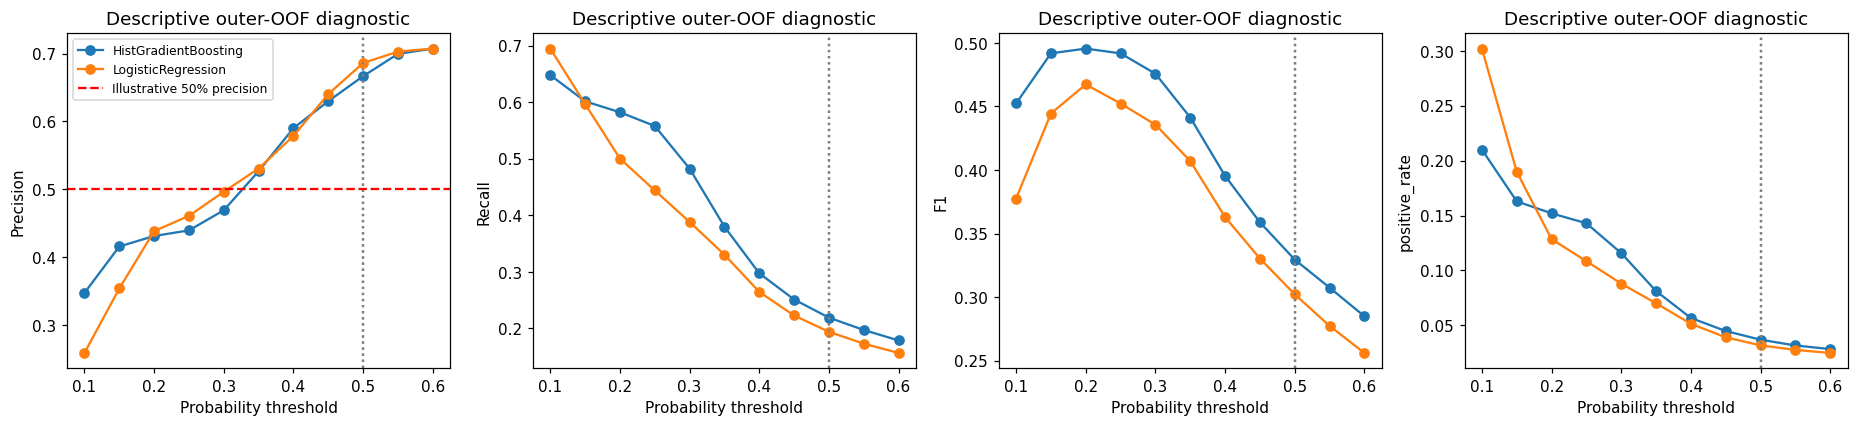

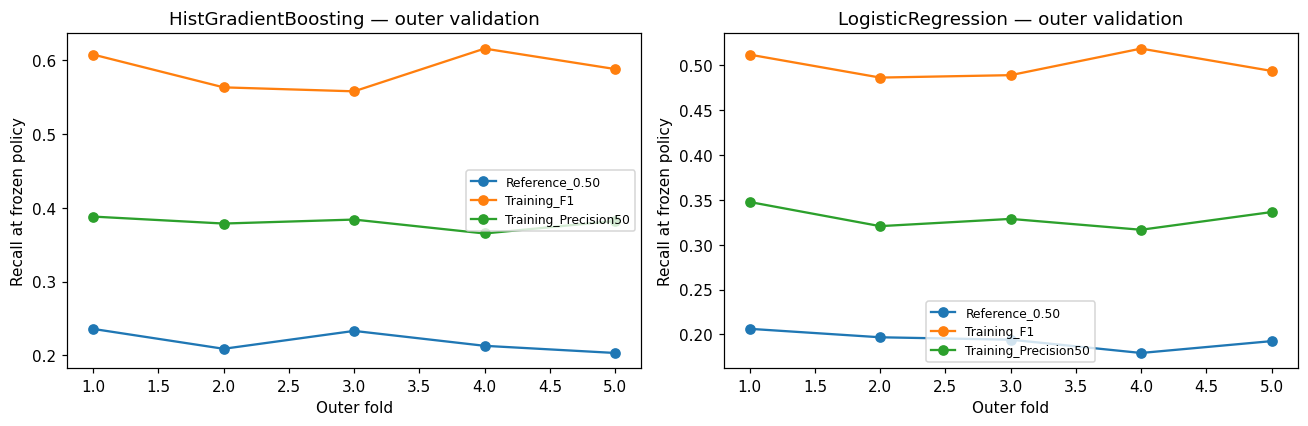

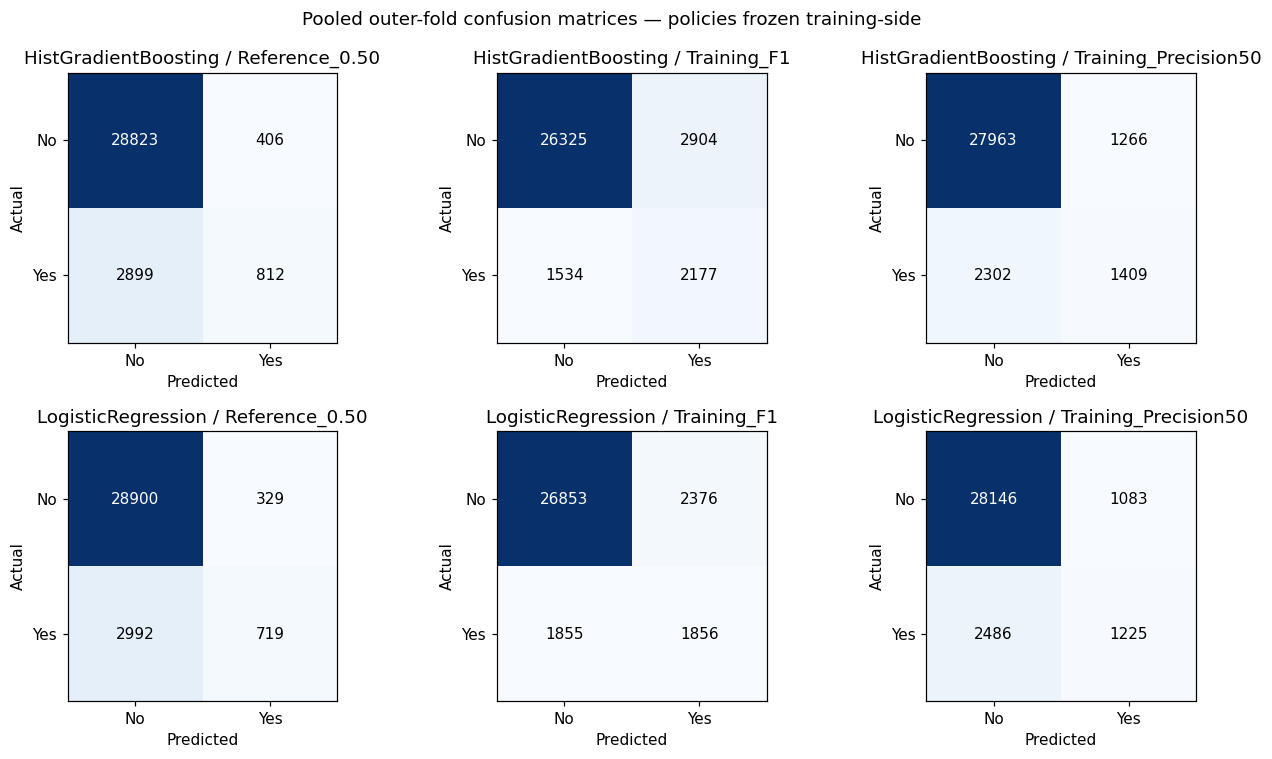

In [5]:
fig,axes=plt.subplots(1,4,figsize=(17,4))
for model in MODELS:
    d=diagnostic.loc[diagnostic.model.eq(model)]
    for ax,metric in zip(axes,['Precision','Recall','F1','positive_rate']):
        ax.plot(d.threshold,d[metric],marker='o',label=model);ax.axvline(.5,color='gray',ls=':')
        ax.set(xlabel='Probability threshold',ylabel=metric,title='Descriptive outer-OOF diagnostic')
axes[0].axhline(.5,color='red',ls='--',label='Illustrative 50% precision');axes[0].legend(fontsize=8)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,model in zip(axes,MODELS):
    d=policy_results.loc[policy_results.model.eq(model)]
    for policy in POLICIES:
        z=d.loc[d.policy.eq(policy)];ax.plot(z.outer_fold,z.Recall,marker='o',label=policy)
    ax.set(xlabel='Outer fold',ylabel='Recall at frozen policy',title=model+' — outer validation');ax.legend(fontsize=8)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(2,3,figsize=(12,7))
for row,model in enumerate(MODELS):
    for col,policy in enumerate(POLICIES):
        ax=axes[row,col];d=pooled_policies.loc[pooled_policies.model.eq(model)&pooled_policies.policy.eq(policy)].iloc[0]
        cm=np.array([[d.TN,d.FP],[d.FN,d.TP]],dtype=int);ax.imshow(cm,cmap='Blues')
        for i in range(2):
            for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
        ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['No','Yes'],yticklabels=['No','Yes'],xlabel='Predicted',ylabel='Actual',title=model+' / '+policy)
fig.suptitle('Pooled outer-fold confusion matrices — policies frozen training-side');plt.tight_layout();plt.show()



## 6. Preservation, warning audit and final report

Confirm all 60 fresh fits and 60 partition-isolated prediction calls, unchanged datasets/split/preprocessing/prior results and no nonfinite outputs. Existing preprocessing unit tests are checked separately. No holdout row is parsed/evaluated and no complete-development fit occurs.

All 15 predictors remain Provisional: age, job, marital, education, default, housing, loan, previous, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed, recency_available, recency_days. Feature timing, customer/date gaps, previous full-data EDA and development-based model/shortlist choices still constrain claims. Training-only threshold selection prevents direct evaluation-label leakage, not every feature-timing/generalization issue.

Recommend only future approved imbalance comparisons, e.g. class weighting versus these threshold-only references, with identical outer isolation. Mixed-type resampling must respect categories; no improvement is assumed and no resampling is executed. Team must define costs, incremental benefit, capacity and any actual precision target. Stop after Phase 5B-1; no commit or push.


In [6]:
for name,digest in input_hashes.items():assert sha(PROJECT_DIR/name)==digest,name+' modified'
pd.testing.assert_frame_equal(dev,snapshot,check_exact=True)
assert all(row['status']=='PASS' for row in FIT_AUDIT+PRED_AUDIT)
fit_summary=pd.DataFrame(FIT_AUDIT).groupby(['model','role','rows']).size().rename('fits').reset_index()
pred_summary=pd.DataFrame(PRED_AUDIT).groupby(['model','role']).size().rename('calls').reset_index()
cost_summary=cost.groupby('model').agg(training_OOF_fits=('training_OOF_fits','sum'),outer_refits=('outer_refits','sum'),wall_seconds=('wall_seconds','sum'))
print('All 60 fresh fits and 60 prediction calls passed; original artifacts unchanged; holdout unused.')

def mdtable(frame,index=False):
    t=frame.reset_index() if index else frame.copy()
    def fmt(v):return f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v).replace('|',' / ').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,t.columns))+' |','| '+' | '.join(['---']*len(t.columns))+' |']+['| '+' | '.join(fmt(v) for v in r)+' |' for r in t.itertuples(index=False,name=None)])
warning_text=mdtable(pd.DataFrame(WARNING_LOG)) if WARNING_LOG else 'None recorded across all 60 fits.'
training_selection=pd.DataFrame(training_tables)
elapsed=time.perf_counter()-started
summary=f"""# Phase 5B-1 — Threshold and business decision-policy analysis

## Scope, latest-main provenance and economical reuse

Started from latest fetched main **{BASE_MAIN}**, including merged Phase 5A; local branch fast-forwarded without creating a commit. Reviewed preprocessing.py, cleaned data/saved split, Phase 3/4/4B summaries and Phase 5A notebook/summary. No prior artifacts are modified.

Phase 5A persisted neither fitted estimators nor row-level probability artifacts. It did persist each outer fold's hyperparameters, selected by inner five-fold AP on outer-training data only. We verified its executed code uses search.fit(outer_X,outer_y), records search.best_params_, and uses the same fold recipe. Those approved parameter decisions are reused exactly; every saved value belongs to the exact approved Phase 5A grids. No final parameters are selected from outer outcomes. Repeating the same grids is unnecessary, so only the selected pipelines are regenerated: **50 training-side OOF fits and 10 outer-training refits = 60 fits**, versus 535 fits if the LR/HGB grids were repeated. RF is imported as a historical comparison, not rerun.

The 0.50 outer-fold scores reproduced all six Phase 5A metrics at their published six-decimal precision; pooled Top-K counts/metrics also reproduced Phase 5A. This consistency check validates regeneration and does not change parameters based on outer scores.

## Data integrity and leakage boundaries

Cleaned SHA-256 `{input_hashes['02_cleaned_dataset.csv']}` matched saved split before applying positions, binding row ordering and values. Saved development=32,940, held-out=8,236; positions verified unique/disjoint/exhaustive. Only development CSV rows were parsed. Outer StratifiedKFold(5,shuffle=True,random_state=42), checksum `{outer_hash}`, matches Phase 5A. No new train-test split. Original CSV if present was only byte-hashed, not parsed for modeling.

Inside each outer-training partition, we regenerated selected-model OOF probabilities using five training-side folds (same inner configuration). Each prediction excludes its own row from fitting; preprocessing is fresh per fit. Hyperparameters were selected previously using all of that outer-training partition, including training-side OOF labels during earlier inner scoring. Thus these probabilities are cross-fitted conditional on training-selected hyperparameters, **not an unbiased inner performance estimate**. They are used solely to fit the threshold, never as final evaluation. Outer-validation labels influence neither hyperparameters nor thresholds. Both threshold policies are frozen before outer predictions and label evaluation. The outer layer evaluates the complete reused-HP-selection-plus-threshold procedure; prior development exploration and shortlist choice remain limitations.

LR reuses approved one-hot, ordinary StandardScaler and available-only ConditionalRecencyScaler unchanged. HGB reuses unscaled tree one-hot/numerical factory, categorical_features=None, early_stopping=False. All seeds=42, weights=None. Numeric guards do not transform values. No whole-development preprocessing, resampling, feature selection, new model family or RF search. Threshold rule is probability >=t, consistent with prior >=0.50 convention.

## Predeclared threshold objectives and rules

Grid: {GRID.tolist()}; 0.50 retained unchanged. F1 policy maximizes training-side OOF F1, exact ties choose the highest threshold. Precision-constrained policy maximizes recall among thresholds with positive contact volume and empirical training-side precision >=50%; ties choose higher precision, then higher threshold. The **50% target is an illustrative research assumption, not a bank policy or guaranteed future precision**.

If no candidate is feasible, record none feasible and abstain (zero contacts) on that outer cohort; precision is reported with zero_division=0, not as satisfying the constraint. Synthetic tests verified this branch and deterministic tie-breaking. In all cases outer precision can fall below the training target; report actual validation behavior rather than silently retuning. Repeating selector calls on identical training-side predictions reproduced thresholds.

## Selected thresholds and stability — training-side decisions only

{mdtable(thresholds)}

Training_OOF_precision/recall here are threshold-fitting diagnostics, not unbiased evaluation.

{mdtable(stability)}

All training-side candidate threshold scores (for audit, not independent performance):

{mdtable(training_selection)}

## Proper outer-validation policy results

Each selected policy is evaluated once per outer fold. Accuracy/precision/recall/F1 and contact counts depend on threshold; ROC-AUC/AP use the unchanged positive probabilities. AP is Average Precision, not trapezoidal PR area. zero_division=0 throughout. Confusion matrices use actual rows no/yes, predicted columns no/yes: [[TN,FP],[FN,TP]].

{mdtable(policy_results)}

Five-fold mean ± sample SD (ddof=1); counts are average contacts per outer-validation cohort, positive_rate is a fraction:

{mdtable(comparison,index=True)}

Pooled outer-policy diagnostics, aggregating predictions made with each fold's own frozen threshold:

{mdtable(pooled_policies)}

Pooled counts are integer totals; pooled precision/F1 need not equal mean fold metrics. For the same fixed probabilities, changing threshold **does not change ROC-AUC or AP**. Assertions verify identical ranking metrics across policies within each outer fold and all descriptive curves. No ranking gain is attributed to threshold movement.

Illustrative constraint achieved on outer folds (not a guaranteed policy):

{mdtable(constraint_status,index=True)}

## Descriptive threshold curves — not a policy-selection score

The following fixed-grid results use pooled outer-OOF probabilities and their labels only to describe the precision/recall/F1/volume trade-off. No threshold is selected from this table or plotted maxima and called unbiased performance. The actual policy thresholds above were fixed training-side before outer evaluation. These views must remain distinct.

{mdtable(diagnostic)}

## Policy A: fixed contact capacity — outer OOF rankings

Rank top 5%,10%,20% with K=ceil(fraction*N), descending probability and saved cleaned-row position for deterministic outcome-independent ties. Precision@K=captured/K, Recall@K=captured/actual subscribers, Lift@K=Precision/cohort prevalence. A fixed probability threshold is not needed. All models contact equal numbers within each comparison view. Include RF's unchanged Phase 5A results; no RF search or new predictions.

{mdtable(capacity_comparison)}

Fold-local mean/SD, including historical RF reference:

{mdtable(local_comparison)}

Pooled probabilities originate from five fitted models and may differ in calibration; fold-local rankings are cleaner per-cohort comparisons. Ceil rounding means pooled and summed fold-local capacities differ slightly. These are historical subscriber-identification metrics, not causal effects of outreach. No known costs, incremental revenue or operational capacity were assumed.

## Policy B: fixed probability rule versus fixed capacity

Reference .50 and both training-selected rules above produce **variable contact volume** by model/fold. F1 maximization balances precision/recall implicitly, not bank profit. The 50% precision-constrained rule sacrifices coverage for an illustrative empirical precision target that is not guaranteed out of sample. Neither rule is financially optimal without costs, incremental value and bank constraints.

If the operational goal is a firm call budget (e.g. contact only 5–20%), a top-K policy directly enforces that capacity and permits like-for-like model comparisons. It is not automatically universally better: a genuinely calibrated probability plus validated utility/cost rule may suit a different objective. No calibration experiment or financial threshold was run. Compare the observed contact rates and capture/precision tables before a team chooses a policy.

RF .50 historical fold metrics for reference only (no threshold adjustment or RF tuning):

{mdtable(rf_reference)}

## Technical checks, warnings and cost

{mdtable(fit_summary)}

{mdtable(pred_summary)}

{mdtable(cost)}

{mdtable(cost_summary,index=True)}

Elapsed through experiments/plots: {elapsed:.2f}s, sklearn {sklearn.__version__}, pandas {pd.__version__}, NumPy {np.__version__}; local execution, not a live hosted Colab session. threadpoolctl limits native threads to one. Standard Colab packages with sklearn >=1.2 suffice; required uploads are listed in the notebook. No previous grids were rerun.

All 60 fits started fresh and were restricted to training-side folds or the current outer-training refit. Every OHE vocabulary equals fitting-row levels; LR mean/variance/scale/sample counts match fit rows; ConditionalRecencyScaler statistics use only available fitting recencies, with zero unavailable standardized values and an unscaled indicator. HGB numbers/recency exactly equal validation input; no 999 sentinel. Probability column mapped by classes_=[0,1]. Each prediction is disjoint from its estimator's fitting rows. Outer prediction is blocked until thresholds are frozen. No whole-development or held-out fitting, no NaN/infinity, no changes in fitted parameters on transform. Hashes and development equality confirm raw/cleaned data, split, approved preprocessing and earlier results unchanged. All four existing standalone preprocessing tests passed when rerun separately.

Warnings/errors:

{warning_text}

## Interpretation, limitations and Phase 5B-2 recommendations

Use measured outer-fold mean/SD and pooled confusion/volume tables to judge recall gains and precision cost. Selected thresholds are research policy experiments, not final deployment choices. No best pooled-diagnostic threshold is declared. Outer ranking metrics remain exactly those of the fixed probability predictions.

All 15 predictors remain Provisional: {', '.join(FEATURES)}. Historical recency/contact cutoff, campaign-start customer/status snapshots, economic publication/revision vintages and outcome window still need timestamped confirmation. Missing customer IDs/dates permit repeated-client/temporal overlap in random stratified CV. Prior full-data EDA and development-based family/grid/shortlist exploration also limit generalization claims. Threshold isolation controls direct fitting/evaluation leakage; it does not certify feature timing, unseen-client/future-period performance, deployment readiness or causal call impact.

For a separately approved Phase 5B-2, compare class weighting against these threshold-only references under the same outer isolation, and consider resampling only with appropriate mixed-type methods and training-fold-only application. Any sampling method must respect categorical indicators and avoid standard SMOTE generating invalid fractional category combinations. No improvement is claimed before experiments. Do not change saved holdout, fit globally before CV, or use threshold changes to claim AP improvement. Team approval needed for imbalance methods, model/policy shortlist, business capacity/error costs, illustrative precision target and timing assumptions. No SMOTE, undersampling, class weighting, feature selection, held-out evaluation, commit/push or Phase 5B-2 was performed.

Deliverables: executed 07_threshold_decision_analysis.ipynb and this 07_threshold_decision_summary.md, saved in the repository; stop pending review.
"""
(PROJECT_DIR/'07_threshold_decision_summary.md').write_text(summary)
print('Saved Phase 5B-1 report; stop before imbalance experiments/commit/push.')


All 60 fresh fits and 60 prediction calls passed; original artifacts unchanged; holdout unused.
Saved Phase 5B-1 report; stop before imbalance experiments/commit/push.


## Observed policy trade-offs and stability

Mean outer-fold HGB recall rises from 21.88% at 0.50 to 58.66% under training-side F1 selection, with precision falling from 66.77% to 42.85% and F1 rising from 0.3292 to 0.4951. Mean contact rate rises from 3.70% to 15.43%. LR recall rises from 19.37% to 50.01%, precision falls from 68.69% to 43.87%, and F1 rises from 0.3021 to 0.4673; contact rate rises from 3.18% to 12.85%. These are evaluated frozen-policy effects on decisions, not improvements in AP/ROC-AUC or causal outreach response.

F1 selects 0.20 for LR in all five folds; HGB selects 0.20 in four and 0.15 in one. The research precision constraint selects 0.35 in every fold for both models. All training partitions had a feasible candidate, and every outer cohort empirically achieved at least 50% precision. Mean HGB precision/recall at that policy is 52.72%/37.97%, versus LR 53.13%/33.01%; mean contact rates are 8.12% and 7.01%. Passing five observed cohorts is not a guaranteed lower precision bound on new customers.

Pooled HGB contact volume changes from 1,218 at 0.50 to 5,081 under F1 selection, capturing 2,177 versus 812 historical subscribers. The precision-constrained policy contacts 2,675 and captures 1,409. If an illustrative budget were exactly 10% (3,294), top-K HGB instead captures 1,628 with 49.42% precision and 43.87% recall; it enforces capacity directly, while the precision/F1 rules pursue different objectives and contact different numbers. That conditional comparison does not establish a known bank budget or a financially optimal policy.

Use this phase's threshold-only gains as a reference before adding imbalance-treatment complexity. Next approved experiments should distinguish ranking improvements (AP/ROC-AUC) from decision-rule effects and compare policies at a bank-approved capacity or objective; simply lowering a threshold is already a substantial recall/precision trade-off.

